# Projet complexité

Réalisé par :


## 1. Introduction

### 1.1 Points mathématique

La complexité d'un programme s'inspire principalement de ce qui s'appelle en termes mathématiques l'**analyse asymptotique**. L'analyse asymptotique est le domaine mathématique qui étudie relativement la convergence entre fonctions : sont-elles équivalents? L'une domine-t-elle l'autre? 



#### 1.1.1 Vocabulaire et définitions

En mathématiques, l'analyse asymptotique se base principalement sur des **limites de fonctions**. On considère une variable $\alpha$ deux fonctions à valeur dans $\mathbb{R}$, $f(x)$ et $g(x)$, sachant que $g$ ne vaut pas 0 autour de $\alpha$. 

On dépeint trois sortes de comportements en analyse asymptotique :

 - si $\lim\limits_{x \rightarrow \alpha} \frac{f(x)}{g(x)} = 1$, on dit que **$f$ est équivalent à $g$ en $\alpha$** et on le note $f \underset{x \rightarrow \alpha}{\sim} g$.
 - si $\exists C\in \mathbb{R}, \lim\limits_{x \rightarrow \alpha} \frac{f(x)}{g(x)} = C$, c'est-à-dire que $\frac{f(x)}{g(x)}$ tend vers une constante (nulle ou non), on dit que **$g$ domine $f$ en $\alpha$** et on le note $f(x)=\underset{x \rightarrow \alpha}{O}(g(x))$. En particulier, lorsque $f \underset{x \rightarrow \alpha}{\sim} g$, $g$ domine $f$ et $f$ domine $g$ en $\alpha$.
 - si  $\lim\limits_{x \rightarrow \alpha} \frac{f(x)}{g(x)} = 0$, alors on dit que **$f$ est négligeable en $\alpha$ devant $g$** et on le note $f(x)=\underset{x \rightarrow \alpha}{o}(g(x))$.

#### 1.1.2 Exemples

Soit $f$ et $g$ deux fonctions définies comme suit : 

$$
\begin{align*}
f
\colon
\begin{cases}
\mathbf{\mathbb{R}} & \longrightarrow\mathbb{R}\\
x&\longmapsto \frac{1}{x^2}
\end{cases}
\end{align*}
$$
$$
\begin{align*}
g\colon
\begin{cases}
\mathbf{\mathbb{R}} & \longrightarrow\mathbb{R}\\
x&\longmapsto \frac{1}{x}
\end{cases}
\end{align*}
$$

On a : 
$$
\frac{f(x)}{g(x)} = \frac{\frac{1}{x^2}}{\frac{1}{x}} = \frac{x}{x^2} = \frac{1}{x} \underset{x \rightarrow +\infty}{\longrightarrow}0
$$
et donc $f = \underset{x \rightarrow +\infty}{o}(g(x))$.

À l'inverse, 

$$
\frac{g(x)}{f(x)} = \frac{\frac{1}{x}}{\frac{1}{x^2}} = \frac{x^2}{x} = {x} \underset{x \rightarrow 0}{\longrightarrow}0
$$
et donc $g = \underset{x \rightarrow 0}{o}(f(x))$.

On remarquera d'ailleurs que ni $f$, ni $g$, ne sont définies ni en $0$, ni en $+\infty$, ce qui fait la force de l'analyse asymptotique. 

Un dernier exemple est celui de la suite $u_n=n!$. D'après la formule de Stirling, on a : 
$$n! \sim \sqrt{2 \pi n} (\frac{n}{e})^n$$

#### 1.1.3 Remarques et propriétés importantes

Il est important de noter les points suivants : 

 - Si $f(x)=\underset{x \rightarrow \alpha}{O}(g(x))$ et que $\lim\limits_{x \rightarrow \alpha} \frac{f(x)}{g(x)} \ne 0$, alors $g(x)=\underset{x \rightarrow \alpha}{O}(f(x))$ ; il suffit d'inverser $f$ et $g$ pour vérifier cette propriété.

 - Si $f(x) \sim g(x)$, alors $g(x) \sim f(x)$ ; il s'agit d'un cas particulier de la propriété précédente.

 - Si $f = \underset{x \rightarrow \alpha}{o}(g(x))$, alors $f = \underset{x \rightarrow \alpha}{O}(g(x))$ ; il s'agit du cas où $C = 0$.

 - Si $f = \underset{x \rightarrow \alpha}{O}(g(x))$ et $g = \underset{x \rightarrow \alpha}{O}(h(x))$, alors $f = \underset{x \rightarrow \alpha}{O}(h(x))$ ; de même, si $f = \underset{x \rightarrow \alpha}{o}(g(x))$ et $g = \underset{x \rightarrow \alpha}{o}(h(x))$, alors $f = \underset{x \rightarrow \alpha}{o}(h(x))$.


### 1.2. Application à l'informatique

#### 1.2.1. Lien entre informatique et mathématique

En informatique, on ne travaille non plus avec des fonctions réelles, mais des fonctions discrètes, c'est-à-dire des suites. Elles ont pour particularité de ne pas être continues. 

Considérons par exemple le programme python suivant, destiné à calculer une multiplication par des opérations simples (la syntaxe est celle de python3.7+, supportant les [type hints](https://docs.python.org/3/library/typing.html)):
```python
def multiplicate(x: int, y: int) -> int:
    """
    Cette fonction multiplie a et b en utilisant l'algorithme de multiplication
    à la russe (voir TD0, exercice 5). 
    """
    r = 0 
    while x != 0:
        if x%2 == 1:
            r += y
            x -= 1
        x /= 2
        y *= 2
    return r
```

On remarque l'instruction *while*, dans laquelle les 3 variables `x`, `y` et `r` sont modifiées. 

On peut donc les renommer, non plus `x`, `y` et `r`, mais plus mathématiquement $x_n$, $y_n$, $r_n$. On a donc $x_0=x$, $y_0=y$, $r_0=0$. 

Ensuite, les éléments suivants de la suite sont définis récursivement : 

$$
\forall n \in \mathbb{N}, 
x_{n+1} =
\begin{cases}
\frac{x_n - 1}{2} & \text{si } x_n \text{ est impair} \\
\frac{x_n}{2} & \text{sinon}
\end{cases}
$$

$$
\forall n \in \mathbb{N}, 
y_{n+1} = y_n*2
$$

$$
\forall n \in \mathbb{N}, 
r_{n+1} = 
\begin{cases}
r_n + y_n & \text{si } x_n \text{ est impair} \\
r_n & \text{sinon}
\end{cases}
$$

On remarquera par ailleurs l'*invariant de boucle* permettant de garantir la bonne fonctionnalité du programme, à savoir que : 

$$
\forall n \in \mathbb{N}, x_n y_n + r_n = x y
$$

En particulier, à la fin de la boucle, on sait que $x_n=0$, donc $x_n y_n + r_n = x y \Leftrightarrow r_n = x y$, et donc la variable `r` contient bien le résultat de `x` multiplié par `y` une fois sorti de la boucle. 

#### 1.2.2 Utilisation de l'analyse asymptotique

Là où l'analyse asymptotique d'une fonction entre en jeu, c'est lorsque l'on souhaite connaître le comportement d'une fonction, en fonction des données entrées en argument. C'est surtout le cas lorsqu'on utilise des boucles, qui sont succeptibles de devoir être exécutées plus longtemps lorsqu'on se rapproche du *pire des cas*, c'est-à-dire lorsque les données entrés en argument sont particulièrement longues à traiter pour obtenir le résultat souhaité ou terminer la procédure. 

Observons à nouveau le programme utilisé précédemment (la fonction multiplicate).

```python
def multiplicate(x: int, y: int) -> int:
    """
    Cette fonction multiplie a et b en utilisant
    l'algorithme de multiplication à la russe (voir TD0, exercice 5). 
    """
    r = 0 
    while x != 0:
        if x%2 == 1:
            r += y
            x -= 1
        x /= 2
        y *= 2
    return r
```

On remarque tout particulièrement qu'à chaque itération, `x` est divisé par 2, et éventuellement décrémenté lorsqu'il est impair. Puisque toutes les puissances de 2 sont paires, on peut prouver la propriété qui suit : 

$$
\forall x \in \mathbb{N}, c(x)=\lfloor log2(x) \rfloor
$$

où $c(x)$ désigne le nombre d'itérations de la boucle en fonction de $x$, et $log2$ le logarithme en base 2 ($log2(x) = \frac{ln(x)}{ln(2)}$).

Le coefficient $c$ s'apparente à la *complexité* du programme, c'est-à-dire qu'on peut déterminer le comportement de la fonction à partir de $c$. 

Comme $c$ se décline selon un nombre d'itérations (donc d'opérations), il est proportionnel au temps pris pour exécuter la fonction, que l'on nomme $C$ (en majuscule). $C$ est appelé *complexité en temps*. Il existe aussi une *complexité en mémoire*, consistant à considérer la quantité utilisée en mémoire dans un programme (par exemple récursif ou traitant des listes chaînées). 

Puisqu'on ne connaît pas le temps pris par une opération du programme, on ne note donc pas : $C(x) = \lfloor log2(x) \rfloor$ mais : 

$$
C(x) = O(log2(x))
$$

ou tout simplement, puisque $log2$ et $ln$ sont proportionnelles entre elles : 

$$
C(x) = O(ln(x))
$$

Ce coefficient $C(x)$ nous permet de plus de comparer plusieurs programmes entre eux, et de déterminer quel fonction est plus avantageuse à utiliser. 

Observons par exemple la fonction de multiplication définie en python ci-dessous :
```python
def multiplicate_naively(x: int, y: int) -> int:
    """
    Cette fonction multiplie a et b de manière naïve. 
    """
    r = 0
    while x != 0:
        r += y
        x -= 1
    return r
```

En bref, la fonction `multiplicate_naively` multiplie `x` par `y` en additionnant `y`, `x` fois. Sa complexité est donc : 
$$
C_2(x) = O(x)
$$

En comparant les deux fonctions, on observe aisément que : 
$$
C(x) = o(C_2(x))
$$

Donc la complexité de la méthode russe est clairement plus intéressante que la méthode naïve, puisque c'est elle qui grandira le moins vite lorsque la variable `x` augmentera.

On dit que la complexité temporelle de `multiplicate` est logarithmique, et que celle de `multiplicate_naively` est linéaire.

## 2. La théorie de la complexité

La complexité est une branche des mathématiques, plus particulièrement de l'informatique théorique,
qui analyse de manière formelle le temps de calcul, la mémoire utilisée (et parfois d'autres ressources
comme la taille des circuits, le nombre de processeurs ou l'énergie consommée) nécessaires à un algorithme
pour résoudre un problème. Elle consiste à évaluer la difficulté intrinsèque des problèmes,
à les classer selon leur complexité, et à examiner les relations entre ces différentes classes.



## 3 Génération d'une instance de TSP

La génération des points se fait dans le carré $[0,1]^2$.

In [183]:
import numpy as np

In [184]:
def generate_tsp_instance(n, seed=None):
    """
    Génère une instance TSP aléatoire de taille n.
    Args:
        n: nombre de villes
        seed: seed pour la reproductibilité
    Returns:
        Matrice de distance n x n
    """
    if seed is not None:
        np.random.seed(seed)
    
    # Génération de coordonnées aléatoires
    coords = np.random.rand(n, 2)
    
    # Calcul de la matrice de distance euclidienne
    dist_matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i != j:
                dist_matrix[i, j] = np.linalg.norm(coords[i] - coords[j])
    
    return dist_matrix, coords

In [185]:
# Génère une instance avec 10 villes
distances, coordinates = generate_tsp_instance(5, seed=42)
distances

array([[0.        , 0.5017136 , 0.82421549, 0.32755369, 0.33198071],
       [0.5017136 , 0.        , 0.72642889, 0.72506609, 0.17058938],
       [0.82421549, 0.72642889, 0.        , 0.71690251, 0.7091551 ],
       [0.32755369, 0.72506609, 0.71690251, 0.        , 0.56557921],
       [0.33198071, 0.17058938, 0.7091551 , 0.56557921, 0.        ]])

## 4. Résolution du TSP par Force Brute

### 4.1 Principe de l'algorithme

L'algorithme de force brute teste **toutes les permutations possibles** des villes pour trouver la solution optimale du problème du voyageur de commerce (TSP). 

**Fonctionnement :**
- Génère toutes les permutations possibles de visites des villes
- Pour chaque permutation, calcule la distance totale du cycle Hamiltonien
- Conserve la meilleure solution trouvée

**Complexité :** O(n!) - factorial, donc **seulement praticable pour n ≤ 10**

### 4.2 Utilisation du code

```python
# Générer une instance
distances, coords = generate_tsp_instance(5, seed=42)
# Résoudre par force brute
distance_opt, chemin_opt = tsp_brute_force(distances)

print(f"Distance optimale: {distance_opt:.2f}")
print(f"Chemin: {chemin_opt}")
```

**Note :** Pour n=10, il y a 3 628 800 permutations à tester. Pour n=15 : 1,3 trillion.

In [186]:
import itertools

In [187]:
def tsp_brute_force(dist_matrix):
    """
    Résout le TSP par force brute.
    Args:
        dist_matrix: matrice de distance n x n
    Returns:
        (meilleure_distance, meilleur_chemin)
    """
    n = len(dist_matrix)
    villes = list(range(n))
    
    meilleure_distance = float('inf')
    meilleur_chemin = None
    
    # Teste toutes les permutations possibles
    for perm in itertools.permutations(villes[1:]):
        chemin = [0] + list(perm) + [0]  # Commence et termine à la ville 0
        distance = 0
        
        # Calcule la distance totale du chemin
        for i in range(len(chemin) - 1):
            distance += dist_matrix[chemin[i]][chemin[i + 1]]
        
        # Met à jour si meilleure solution trouvée
        if distance < meilleure_distance:
            meilleure_distance = distance
            meilleur_chemin = chemin[:-1]  # Enlève le dernier 0
    
    return meilleure_distance, meilleur_chemin

In [188]:
distances, _ = generate_tsp_instance(5, seed=42)
distance, chemin = tsp_brute_force(distances)
print(f"Distance optimale: {distance:.4f}")
print(f"Chemin optimal: {chemin}")

Distance optimale: 2.2735
Chemin optimal: [0, 3, 2, 1, 4]


## 6. Résolution du TSP par l’algorithme de Christofides et Serdyukov

### 6.1 Principe de l’algorithme

**L’algorithme de Christofides et Serdyukov** est une méthode approchée pour résoudre le problème du voyageur de commerce dans le cas **métrique**, c’est-à-dire lorsque les distances sont **symétriques** et respectent **l’inégalité triangulaire**.

**Principe général :**

- Construire le graphe complet pondéré reliant toutes les villes.

- Calculer un arbre couvrant minimal (MST) reliant tous les sommets avec un coût minimal.

- Identifier les sommets de degré impair dans le MST.

- Trouver un appariement parfait minimum entre ces sommets.

- Fusionner le MST et l’appariement pour obtenir un graphe eulérien.

- Trouver un cycle eulérien, puis le transformer en cycle hamiltonien.

**Complexité :**

Calcul du MST : O(n² log n)

Appariement parfait minimum : O(n³)

Construction du cycle : O(n)

**Complexité totale : O(n³)**

### 6.2 Utilisation du code

In [ ]:
!pip install networkx
!pip install networkx matplotlib

In [190]:
import networkx as nx
import matplotlib.pyplot as plt
import itertools
import random

In [191]:
def tsp_christofides(distances, coords):
    """
    Implémentation de l'algorithme de Christofides et Serdyukov pour le TSP métrique.
    Compatible avec la fonction generate_tsp_instance(n) qui renvoie (distances, coords).
    
    :param distances: matrice des distances (n x n)
    :param coords: dictionnaire {i: (x, y)} représentant les villes
    :return: (chemin, distance_totale)
    """
    n = len(coords)
    
    # Étape 1 : création du graphe complet pondéré
    G = nx.Graph()
    for i in range(n):
        for j in range(i + 1, n):
            G.add_edge(i, j, weight=distances[i][j])

    # Étape 2 : arbre couvrant minimal (MST)
    mst = nx.minimum_spanning_tree(G, weight='weight')

    # Étape 3 : sommets de degré impair
    odd_nodes = [v for v in mst.nodes if mst.degree(v) % 2 == 1]

    # Étape 4 : appariement parfait minimum (version compatible NetworkX 3.x)
    subgraph = G.subgraph(odd_nodes)
    matching = nx.algorithms.matching.min_weight_matching(subgraph, weight='weight')

    # Étape 5 : fusion MST + appariement
    multigraph = nx.MultiGraph()
    multigraph.add_edges_from(mst.edges(data=True))
    multigraph.add_edges_from(((u, v, {'weight': G[u][v]['weight']}) for u, v in matching))

    # Étape 6 : cycle eulérien puis hamiltonien
    euler_cycle = list(nx.eulerian_circuit(multigraph))
    visited = set()
    chemin = []
    total_dist = 0

    for u, v in euler_cycle:
        if u not in visited:
            visited.add(u)
            chemin.append(u)
    chemin.append(chemin[0])  # retour à la ville de départ

    # Calcul de la distance totale
    for i in range(len(chemin) - 1):
        total_dist += distances[chemin[i]][chemin[i + 1]]

    return chemin, total_dist



### 6.3 Exemple d’exécution

Distance (Christofides) : 3.58
Chemin : [0, 4, 8, 9, 7, 2, 6, 1, 5, 3, 0]


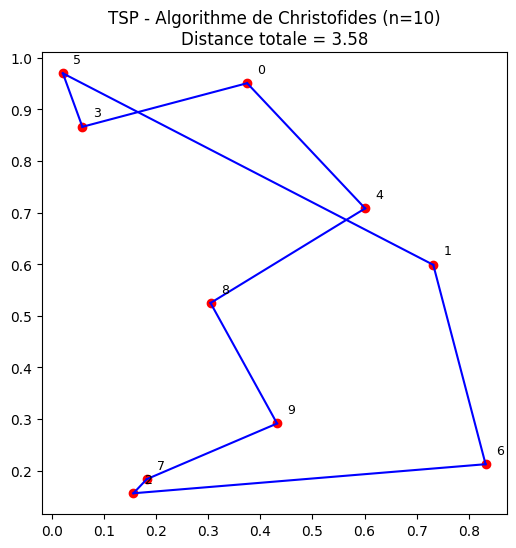

In [192]:
# Générer une instance
distances, coords = generate_tsp_instance(10, seed=42)

# Résoudre par l’algorithme de Christofides
chemin_chr, dist_chr = tsp_christofides(distances, coords)

print(f"Distance (Christofides) : {dist_chr:.2f}")
print(f"Chemin : {chemin_chr}")

# Visualisation du chemin trouvé
plt.figure(figsize=(6, 6))

# Tracer le chemin trouvé par Christofides
for i in range(len(chemin_chr) - 1):
    x1, y1 = coords[chemin_chr[i]]
    x2, y2 = coords[chemin_chr[i + 1]]
    plt.plot([x1, x2], [y1, y2], 'b-')

# Afficher les points et leurs indices
for i in range(len(coords)):
    x, y = coords[i]
    plt.scatter(x, y, c='r')
    plt.text(x + 0.02, y + 0.02, str(i), fontsize=9)

plt.title(f"TSP - Algorithme de Christofides (n={len(coords)})\nDistance totale = {dist_chr:.2f}")
plt.show()



### 6.4 Analyse

- L’algorithme de Christofides fournit des solutions proches de l’optimum, avec une borne garantie à **1,5× l’optimum**.

- Sa **complexité polynomiale O(n³)** le rend beaucoup **plus efficace que la force brute** tout en gardant une excellente qualité de solution.

- Contrairement à la méthode exhaustive, il reste **applicable à des instances plus grandes (n > 20)**.

- Christofides est une **référence** pour les TSP métriques et sert souvent de base à des heuristiques modernes.

## 7. Résolution du TSP par Recherche Locale

### 7.1 Principe général

Les **algorithmes de recherche locale** ne cherchent pas la solution optimale absolue, mais **améliorent progressivement une solution initiale** en explorant son voisinage.
Ils sont particulièrement efficaces pour des instances de taille moyenne à grande, où les méthodes exactes deviennent trop coûteuses.

Idée clé :

- Générer une solution initiale.

- Modifier légèrement cette solution.

- Accepter le changement s’il améliore la distance — ou parfois même s’il la dégrade légèrement (recuit simulé).

- Répéter le processus jusqu’à convergence.

### 7.2 Recherche locale par opérateur 2-opt

L’opérateur 2-opt consiste à supprimer deux arêtes et à reconnecter les segments croisés pour réduire la longueur du circuit.

Complexité :

- Chaque itération teste toutes les paires d’arêtes → O(n²) par itération.

- Nombre d’itérations dépend du critère d’arrêt.

### 7.3 Code de l’algorithme 2-opt

In [193]:
import random
import math
import matplotlib.pyplot as plt

def calcul_distance(chemin, distances):
    total = 0
    for i in range(len(chemin) - 1):
        total += distances[chemin[i]][chemin[i + 1]]
    return total

def two_opt_swap(route, i, k):
    new_route = route[:i] + route[i:k + 1][::-1] + route[k + 1:]
    return new_route

def tsp_2opt(distances, iterations=1000):
    """
    Amélioration de la solution TSP par recherche locale 2-opt.
    :param distances: matrice des distances
    :param iterations: nombre d’itérations de recherche
    :return: (chemin, distance)
    """
    n = len(distances)
    # Génération d'une solution initiale aléatoire
    route = list(range(n))
    random.shuffle(route)
    route.append(route[0])
    best_route = route[:]
    best_distance = calcul_distance(route, distances)

    for _ in range(iterations):
        i, k = sorted(random.sample(range(1, n - 1), 2))
        new_route = two_opt_swap(best_route, i, k)
        new_route.append(new_route[0])
        new_distance = calcul_distance(new_route, distances)
        if new_distance < best_distance:
            best_route, best_distance = new_route, new_distance

    return best_route, best_distance


### 7.4 Recherche locale par opérateur 3-opt

**L’algorithme 3-opt** est une **amélioration du 2-opt**.
Il consiste à **supprimer trois arêtes** dans le cycle du TSP, puis à **reconnecter les segments coupés** de différentes manières afin de réduire la longueur totale du chemin.

Contrairement au 2-opt, qui inverse un seul segment à la fois, le 3-opt explore davantage de configurations possibles, ce qui permet :

- de **sortir plus facilement des minima locaux**,

- d’obtenir une **meilleure qualité de solution**,

- mais au prix d’une **complexité plus élevée**.

Complexité :

- Environ O(n³) (car il faut tester de nombreuses combinaisons de trois arêtes).

- Praticable pour des instances de taille ≤ 20 à 30.

### 7.5 Code de l’algorithme 3-opt

In [198]:
def tsp_3opt(distances, iterations=1000):
    """
    Heuristique de recherche locale 3-opt pour le TSP.
    Explore les améliorations possibles en échangeant trois arêtes.
    
    :param distances: matrice des distances
    :param iterations: nombre d’itérations (par défaut : 1000)
    :return: (chemin, distance_totale)
    """
    n = len(distances)

    # Génération d'une solution initiale aléatoire
    route = list(range(n))
    random.shuffle(route)
    route.append(route[0])
    best_route = route[:]
    best_distance = calcul_distance(best_route, distances)

    for _ in range(iterations):
        # Choisir trois indices distincts
        i, j, k = sorted(random.sample(range(1, n - 1), 3))

        # Générer plusieurs configurations candidates sans modifier best_route
        candidates = []

        # Cas 1 : double inversion
        cand1 = best_route[:i] + best_route[i:j][::-1] + best_route[j:k][::-1] + best_route[k:]
        candidates.append(cand1)

        # Cas 2 : échange segments
        cand2 = best_route[:i] + best_route[j:k] + best_route[i:j] + best_route[k:]
        candidates.append(cand2)

        # Cas 3 : variante inversée
        cand3 = best_route[:i] + best_route[j:k][::-1] + best_route[i:j] + best_route[k:]
        candidates.append(cand3)

        # Cas 4 : autre inversion
        cand4 = best_route[:i] + best_route[i:j][::-1] + best_route[j:k] + best_route[k:]
        candidates.append(cand4)

        # Évaluer chaque candidate
        for cand in candidates:
            new_route = cand[:]  # copie sûre
            # Assure que le chemin se boucle sans doublons excessifs
            if new_route[-1] != new_route[0]:
                new_route.append(new_route[0])
            new_distance = calcul_distance(new_route, distances)
            if new_distance < best_distance:
                best_distance = new_distance
                best_route = new_route[:]  # copier la meilleure route trouvée

    return best_route, best_distance


### 7.6 Exemple d’exécution

Distance (3-opt) : 3.46
Chemin : [2, 7, 9, 8, 13, 3, 5, 0, 12, 4, 1, 6, 10, 14, 11, 2]


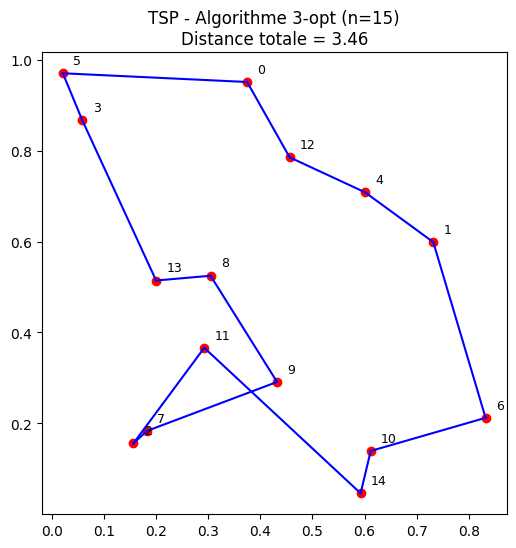

In [199]:
# Génération d’une instance
distances, coords = generate_tsp_instance(15, seed=42)

# Résolution avec 3-opt
chemin_3opt, dist_3opt = tsp_3opt(distances, iterations=2000)

print(f"Distance (3-opt) : {dist_3opt:.2f}")
print(f"Chemin : {chemin_3opt}")

# Visualisation du chemin
plt.figure(figsize=(6,6))
for i in range(len(chemin_3opt) - 1):
    x1, y1 = coords[chemin_3opt[i]]
    x2, y2 = coords[chemin_3opt[i + 1]]
    plt.plot([x1, x2], [y1, y2], 'b-')
for i in range(len(coords)):
    x, y = coords[i]
    plt.scatter(x, y, c='r')
    plt.text(x + 0.02, y + 0.02, str(i), fontsize=9)
plt.title(f"TSP - Algorithme 3-opt (n={len(coords)})\nDistance totale = {dist_3opt:.2f}")
plt.show()


### 7.7 Recuit simulé 

Le **recuit simulé** s’inspire du processus de refroidissement en physique.
Il **autorise parfois des dégradations temporaires** pour **éviter les minima locaux**.

Principe :

- Démarrer avec une température T élevée.

- Explorer le voisinage avec 2-opt.

- Accepter un voisin plus mauvais avec une probabilité exp(-(ΔE/T)).

- Réduire progressivement T.

Complexité :

- Dépend du nombre d’itérations × taille du voisinage → environ O(k × n²).

### 7.8 Code du Recuit Simulé

In [200]:
def tsp_recuit_simule(distances, T_init=100, alpha=0.995, iterations=10000):
    """
    Recuit simulé pour le TSP avec voisinage 2-opt.
    :param distances: matrice des distances
    :param T_init: température initiale
    :param alpha: facteur de refroidissement
    :param iterations: nombre d’itérations
    :return: (chemin, distance)
    """
    n = len(distances)
    route = list(range(n))
    random.shuffle(route)
    route.append(route[0])
    best_route = route[:]
    best_distance = calcul_distance(route, distances)
    current_route = best_route[:]
    current_distance = best_distance
    T = T_init

    for _ in range(iterations):
        i, k = sorted(random.sample(range(1, n - 1), 2))
        new_route = two_opt_swap(current_route, i, k)
        new_route.append(new_route[0])
        new_distance = calcul_distance(new_route, distances)
        delta = new_distance - current_distance

        # Critère d'acceptation
        if delta < 0 or random.random() < math.exp(-delta / T):
            current_route = new_route
            current_distance = new_distance
            if current_distance < best_distance:
                best_route, best_distance = current_route, current_distance

        # Refroidissement
        T *= alpha
        if T < 1e-8:
            break

    return best_route, best_distance


### 7.9 Exemple d’exécution

Distance (2-opt)         : 3.60
Distance (Recuit Simulé) : 3.99


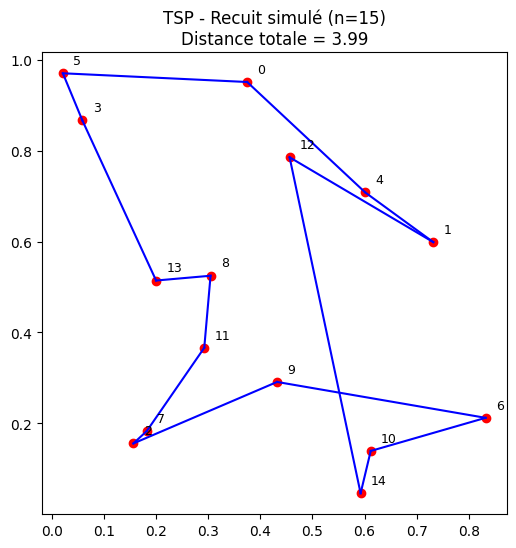

In [201]:
# Génération d’une instance
distances, coords = generate_tsp_instance(15, seed=42)

# Exécution 2-opt
chemin_2opt, dist_2opt = tsp_2opt(distances, iterations=3000)

# Exécution Recuit Simulé
chemin_recuit, dist_recuit = tsp_recuit_simule(distances, T_init=100, alpha=0.995, iterations=5000)

print(f"Distance (2-opt)         : {dist_2opt:.2f}")
print(f"Distance (Recuit Simulé) : {dist_recuit:.2f}")

# Visualisation du meilleur chemin
plt.figure(figsize=(6,6))
for i in range(len(chemin_recuit)-1):
    x1, y1 = coords[chemin_recuit[i]]
    x2, y2 = coords[chemin_recuit[i+1]]
    plt.plot([x1, x2], [y1, y2], 'b-')
for i, (x, y) in enumerate(coords):
    plt.scatter(x, y, c='r')
    plt.text(x+0.02, y+0.02, str(i), fontsize=9)
plt.title(f"TSP - Recuit simulé (n={len(coords)})\nDistance totale = {dist_recuit:.2f}")
plt.show()


### 7.10 Analyse

**Comparaison générale**

- Le **2-opt** est idéal pour une **première amélioration rapide** : simple, efficace, mais limité.

- Le **3-opt** approfondit la recherche et **améliore sensiblement la qualité**, au prix d’un t**emps de calcul supérieur**.

- Le **recuit simulé**, en combinant **hasard et contrôle**, atteint souvent les **meilleures solutions** sans garantie d’optimalité, mais reste **robuste et flexible**.

Donc ces trois approches montrent bien la logique de compromis entre performance et complexité :
plus on veut s’approcher de l’optimum, plus on doit accepter d’augmenter le coût computationnel.
Elles illustrent parfaitement la manière dont les algorithmes approchés permettent de traiter efficacement des problèmes difficiles comme le TSP.